# **Loan Default Analysis**
**Sumber dataset: https://www.kaggle.com/datasets/yasserh/loan-default-dataset**

# **1. Bussiness Problem Understanding**

**Konteks**

Lembaga keuangan memperoleh profit utama melalui bunga dari pinjaman nasabah. Namun, tantangan terbesar industri perbankan adalah risiko gagal bayar (credit risk). Ketika nasabah tidak mampu membayar kembali pinjamannya, bank kehilangan modal pokok dan potensi bunga, yang berakibat pada kerugian finansial yang nyata. Pengambilan keputusan yang salah dalam menyetujui pinjaman adalah ancaman utama bagi stabilitas keuangan bank.

**Target**
* Kelas 1 (Default): Nasabah mengalami gagal bayar.
* Kelas 0 (Non-Default): Nasabah mampu melunasi pinjaman sesuai jadwal.

**Probelm statement**

Proses evaluasi kelayakan kredit nasabah secara manual memerlukan waktu yang lama, biaya operasional tinggi, dan bersifat subjektif (rentan terhadap kesalahan manusia). Jika bank terlalu selektif, mereka akan kehilangan potensi keuntungan dari nasabah yang sebenarnya baik (opportunity cost). Sebaliknya, jika bank terlalu longgar, tingkat kredit macet akan meningkat secara signifikan. Diperlukan sebuah sistem berbasis Machine Learning yang dapat memproses data profil nasabah secara otomatis untuk memprediksi risiko gagal bayar dengan cepat dan objektif.

**Tujuan**
1. Membangun Model Prediktif: Menciptakan model klasifikasi yang mampu mendeteksi potensi gagal bayar sejak tahap awal pengajuan pinjaman.
2. Identifikasi Faktor Utama: Menemukan fitur-fitur yang paling berpengaruh terhadap kegagalan pembayaran nasabah.
3. Digital Transformation: Memodernisasi sistem persetujuan kredit dari manual menjadi otomatis untuk efisiensi waktu dan biaya.

**Metode Analisa**

Pendekatan yang digunakan adalah Supervised Machine Learning karena data memiliki label target yang jelas. Masalah ini masuk ke dalam kategori Binary Classification. Algoritma yang akan diuji meliputi:
* Logistic Regression (sebagai model dasar/baseline).
* Decision Tree dan Random Forest (untuk menangani hubungan non-linear).
* XGBoost atau LightGBM (untuk meningkatkan performa akurasi pada dataset terstruktur).

**Evaluasi Metrik**

Karena dampak finansial dari salah prediksi (nasabah yang aslinya gagal bayar diprediksi aman) sangat besar, maka metrik utama yang digunakan bukan sekadar akurasi, melainkan:
* Recall (Sensitivity): Fokus utama adalah meminimalkan False Negative (nasabah default yang tidak terdeteksi), karena kerugian modal pokok jauh lebih berbahaya daripada kehilangan calon nasabah.
* F1-Score: Digunakan untuk menjaga keseimbangan antara Precision dan Recall.
* ROC-AUC: Mengukur kemampuan model dalam membedakan antara nasabah bermasalah dan nasabah lancar secara keseluruhan.

# **2. Data Understanding**

### Attribute Information
| Attribute | Data Type | Description |
|---|---|---|
| ID | Categorical | Nomor unik identitas pemohon pinjaman |
| year | Categorical | Tahun pengajuan aplikasi pinjaman |
| loan_limit | Categorical | Kategori batasan jumlah pinjaman |
| Gender | Categorical | Jenis kelamin pemohon |
| approv_in_adv | Categorical | Status apakah pinjaman telah disetujui di awal sebelum aplikasi lengkap |
| loan_type | Categorical | Kategori jenis produk pinjaman |
| loan_purpose | Categorical | Tujuan penggunaan uang pinjaman |
| Credit_Worthiness | Categorical | Penilaian kelayakan kredit nasabah |
| open_credit | Categorical | Status apakah nasabah memiliki jalur kredit terbuka |
| business_or_commercial | Categorical | Status apakah pinjaman digunakan untuk keperluan bisnis/komersial atau bukan |
| loan_amount | Numerical | Nilai total uang yang dipinjam dalam angka |
| rate_of_interest | Numerical | Persentase suku bunga tahunan yang dibebankan pada pinjaman |
| Interest_rate_spread | Numerical | Selisih antara suku bunga yang diberikan dengan suku bunga pasar standar |
| Upfront_charges | Numerical | Total biaya administrasi yang dibayarkan nasabah di awal pengajuan |
| term | Numerical | Jangka waktu pelunasan pinjaman yang dihitung dalam satuan bulan |
| Neg_ammortization | Categorical | Status apakah ada fitur amortisasi negatif |
| interest_only | Categorical | Status apakah nasabah hanya membayar bunga saja tanpa mencicil pokok pinjaman selama periode tertentu |
| lump_sum_payment | Categorical | Status apakah pembayaran dilakukan sekali lunas di akhir periode pinjaman |
| property_value | Numerical | Perkiraan nilai pasar dari properti yang dijadikan agunan |
| construction_type | Categorical | Jenis material atau metode konstruksi bangunan properti |
| occupancy_type | Categorical | Status hunian properti yang diagunkan |
| Secured_by | Categorical | Jenis pengamanan aset agunan |
| total_units | Categorical | Jumlah unit properti yang dibiayai atau dijadikan jaminan |
| income | Numerical | Pendapatan bulanan yang dilaporkan oleh pemohon pinjaman |
| credit_type | Categorical | Jenis agensi pelaporan kredit atau tipe catatan kredit |
| Credit_Score | Numerical | Skor numerik yang menunjukkan tingkat kepercayaan kredit nasabah |
| co-applicant_credit_type | Categorical | Jenis catatan kredit dari pemohon penjamin |
| age | Categorical | Rentang usia pemohon |
| submission_of_application | Categorical | DescrMetode pengiriman dokumen aplikasi pinjaman |
| LTV | Numerical | Loan to Value, rasio antara jumlah pinjaman dengan nilai properti agunan |
| Region | Categorical | Wilayah geografis tempat tinggal nasabah |
| Security_Type | Categorical | Jenis metode keamanan hukum terhadap pinjaman |
| Status | Numerical | Label Target. (1 = Default) atau lancar (0 = Non-Default) |
| dtir1 | Numerical | Debt to Income Ratio, persentase pendapatan nasabah yang digunakan untuk membayar hutang |


In [884]:
# --- 1. CORE DATA MANIPULATION ---
import pandas as pd
import numpy as np

# --- 2. DATA VISUALIZATION (EDA) ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- 3. STATISTICAL TRANSFORMATIONS ---
from scipy.stats import boxcox 
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import LabelEncoder

# --- 4. MODELING & PREPROCESSING ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# --- 5. EVALUATION METRICS ---
from sklearn.metrics import classification_report, roc_auc_score

# **3. Load Dataset**

In [885]:
df = pd.read_csv("Loan_Default.csv")
df.head(5)

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


# **4. Overview Data**

In [886]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [887]:
df.describe()

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
count,148670.000000,148670.0,1.486700e+05,112231.000000,112031.000000,109028.000000,148629.000000,1.335720e+05,139520.000000,148670.000000,133572.000000,148670.000000,124549.000000
mean,99224.500000,2019.0,3.311177e+05,4.045476,0.441656,3224.996127,335.136582,4.978935e+05,6957.338876,699.789103,72.746457,0.246445,37.732932
std,42917.476598,0.0,1.839093e+05,0.561391,0.513043,3251.121510,58.409084,3.599353e+05,6496.586382,115.875857,39.967603,0.430942,10.545435
min,24890.000000,2019.0,1.650000e+04,0.000000,-3.638000,0.000000,96.000000,8.000000e+03,0.000000,500.000000,0.967478,0.000000,5.000000
25%,62057.250000,2019.0,1.965000e+05,3.625000,0.076000,581.490000,360.000000,2.680000e+05,3720.000000,599.000000,60.474860,0.000000,31.000000
50%,99224.500000,2019.0,2.965000e+05,3.990000,0.390400,2596.450000,360.000000,4.180000e+05,5760.000000,699.000000,75.135870,0.000000,39.000000
75%,136391.750000,2019.0,4.365000e+05,4.375000,0.775400,4812.500000,360.000000,6.280000e+05,8520.000000,800.000000,86.184211,0.000000,45.000000
max,173559.000000,2019.0,3.576500e+06,8.000000,3.357000,60000.000000,360.000000,1.650800e+07,578580.000000,900.000000,7831.250000,1.000000,61.000000


In [888]:
df.describe(include=object)

,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,Neg_ammortization,interest_only,...,construction_type,occupancy_type,Secured_by,total_units,credit_type,co-applicant_credit_type,age,submission_of_application,Region,Security_Type
count,145326,148670,147762,148670,148536,148670,148670,148670,148549,148670,...,148670,148670,148670,148670,148670,148670,148470,148470,148670,148670
unique,2,4,2,3,4,2,2,2,2,2,...,2,3,2,4,4,2,7,2,4,2
top,cf,Male,nopre,type1,p3,l1,nopc,nob/c,not_neg,not_int,...,sb,pr,home,1U,CIB,CIB,45-54,to_inst,North,direct
freq,135348,42346,124621,113173,55934,142344,148114,127908,133420,141560,...,148637,138201,148637,146480,48152,74392,34720,95814,74722,148637


# **5. Data Cleaning**

##### **Mengecek dan mengatasi Missing Values**

In [889]:
cols_with_nans = [x for x in df if df[x].isnull().sum() > 0]
df[cols_with_nans].isnull().sum()

loan_limit                    3344
approv_in_adv                  908
loan_purpose                   134
rate_of_interest             36439
Interest_rate_spread         36639
Upfront_charges              39642
term                            41
Neg_ammortization              121
property_value               15098
income                        9150
age                            200
submission_of_application      200
LTV                          15098
dtir1                        24121
dtype: int64

In [890]:
# Hitung persentase missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

# 2 angka dibelakang koma
missing_percentage_rounded = missing_percentage.round(2)

# Filter dan Sortir hanya tampilkan yang > 0%
missing_summary_final = missing_percentage_rounded[missing_percentage_rounded > 0].sort_values(ascending=False)

print("Persentase Missing Values per kolom")
print(missing_summary_final)

Persentase Missing Values per kolom
Upfront_charges              26.66
Interest_rate_spread         24.64
rate_of_interest             24.51
dtir1                        16.22
property_value               10.16
LTV                          10.16
income                        6.15
loan_limit                    2.25
approv_in_adv                 0.61
age                           0.13
submission_of_application     0.13
loan_purpose                  0.09
Neg_ammortization             0.08
term                          0.03
dtype: float64


In [891]:
len(df)

148670

**Rows: 148670**

Persentase missing values per kolom
* Upfront_charges             39642 = 26.66%
* Interest_rate_spread        36639 = 24.64%
* rate_of_interest            36439 = 24.51%
* dtir1                       24121 = 16.22%
* property_value              15098 = 10.16%
* LTV                         15098 = 10.16%
* income                      9150 = 6.15%
* loan_limit                  3344 = 2.25%
* age                         200 = 0.13%
* submission_of_application   200 = 0.13%
* approv_in_adv               908 = 0.61%
* loan_purpose                134 = 0.09%
* Neg_ammortization           121 = 0.08%
* term                        41 = 0.03%


In [892]:
df[cols_with_nans].dtypes

loan_limit                    object
approv_in_adv                 object
loan_purpose                  object
rate_of_interest             float64
Interest_rate_spread         float64
Upfront_charges              float64
term                         float64
Neg_ammortization             object
property_value               float64
income                       float64
age                           object
submission_of_application     object
LTV                          float64
dtir1                        float64
dtype: object

Mengecek tipe data setiap kolom yang memiliki missing values

In [893]:
df.isnull().sum().sum()

181135

Total missing values ada 181.135 baris

In [894]:
num_cols = [col for col in df[cols_with_nans].select_dtypes(exclude = 'O')]
cat_cols = [col for col in df[cols_with_nans].select_dtypes(include = 'O')]

def factorize(data):
    for cat_col in data.select_dtypes(include = 'O'):
        data[cat_col] = pd.factorize(data[cat_col])[0]
    return data

def create_split(data, col):
    train = data[data['is_nan'] == 0 ]
    test = data[data['is_nan'] == 1 ]

    X_train = train.drop([col, 'is_nan'], axis=1)
    y_train = train[col]
    X_test = test.drop([col, 'is_nan'], axis=1)
    return X_train, y_train, X_test

def train_predict(mode, X_train, y_train, X_test):
    if mode == 'regression':
        model = LGBMRegressor()
    else:
        model = LGBMClassifier()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    return y_pred

def impute_missing(df, cols_lst, mode):
    for col in cols_lst:
        if df[col].isnull().sum() > int(len(df)/2):
            df.drop(col, axis=1, inplace=True)
            print(f'Dropped {col} because it has more than 50%')
        else:
            data = df.copy()
            nan_ixs = np.where(data[col].isna())[0]
            data['is_nan'] = 0
            data.loc[nan_ixs, 'is_nan'] = 1
            X = data.drop([col], axis=1)
            y = data[col]
            X = factorize(X)
            data = X.join(y)
            X_train, y_train, X_test = create_split(data, col)

            y_pred = train_predict(mode, X_train, y_train, X_test)
            df.loc[nan_ixs, col] = y_pred
    return df

df = impute_missing(df, num_cols, 'regression')
df = impute_missing(df, cat_cols, 'classification')


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.006564 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2078
[LightGBM] [Info] Number of data points in the train set: 112231, number of used features: 29
[LightGBM] [Info] Start training from score 4.045476
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007030 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1921
[LightGBM] [Info] Number of data points in the train set: 112031, number of used features: 28
[LightGBM] [Info] Start training from score 0.441656
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.013335 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not eno

**Mengatasi missing values menggunakn tool Lightgbm**
* Memisahkan tipe data kategorikal dan numerik.
* Membuat kolom flag baru untuk menandakan data kotor menjadi 'is_nan' untuk membedakan data bersih dan kotor.
* Menghapus feature jika ada missing values yang lebih dari 50% dataset.
* Melatih data yang bersih untuk memprediksi isi missing values sehingga bisa lebih akurat.

In [895]:
df.isna().sum().sum()

0

In [896]:
df.duplicated().sum()

0

In [897]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 148670 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              148670 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148670 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           148670 non-null  float64
 12  Interest_rate_spread       148670 non-null  float64
 13  Upfront_charges            14

# **6. Exploratory Data Analysis**

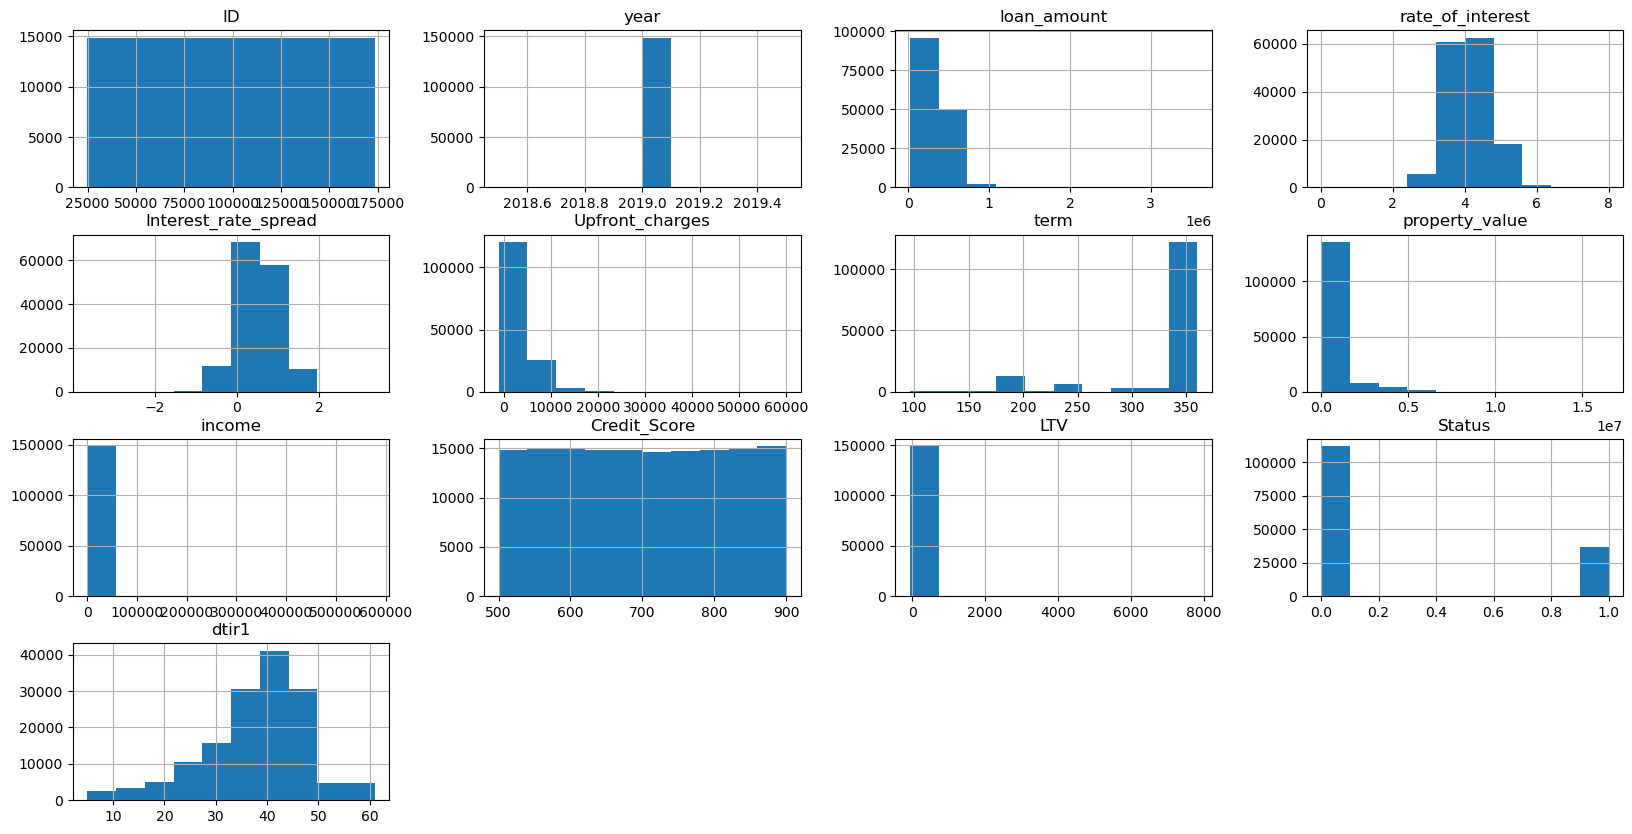

In [898]:
# Creating histogram for those numerical columns that might have an influence towards accepting/rejecting the offer.
df.hist(figsize= [20,10])
plt.show()


Total Records: 148670
Proporsi Non-Default (0): 75.36%
Proporsi Default (1): 24.64%


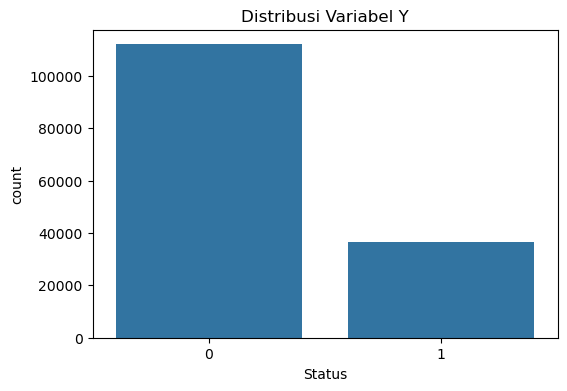

In [899]:
# Mengecek imbalance kolom status (Y)

target_counts = df['Status'].value_counts()
target_proportion = df['Status'].value_counts(normalize=True) * 100

print(f"\nTotal Records: {len(df)}")
print(f"Proporsi Non-Default (0): {target_proportion.get(0, 0):.2f}%")
print(f"Proporsi Default (1): {target_proportion.get(1, 0):.2f}%")

# Visualisasi Imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='Status', data=df)
plt.title('Distribusi Variabel Y')
plt.show()

In [900]:
df.select_dtypes(include=['float64', 'int64']).corr()

,ID,year,loan_amount,rate_of_interest,Interest_rate_spread,Upfront_charges,term,property_value,income,Credit_Score,LTV,Status,dtir1
ID,1.000000,NaN,-0.000566,0.000401,0.002889,-0.006047,-0.003994,0.000777,0.001936,-0.001036,-0.005540,0.001703,-0.004752
year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amount,-0.000566,NaN,1.000000,-0.079100,-0.345456,0.093476,0.174809,0.425391,0.455761,0.004438,0.042617,-0.036825,0.029125
rate_of_interest,0.000401,NaN,-0.079100,1.000000,0.575215,-0.110491,0.243511,0.179689,-0.019969,0.000604,-0.098358,0.371498,0.053083
Interest_rate_spread,0.002889,NaN,-0.345456,0.575215,1.000000,0.003328,-0.133212,-0.077592,-0.132661,0.000164,0.015061,0.261791,0.074167
Upfront_charges,-0.006047,NaN,0.093476,-0.110491,0.003328,1.000000,-0.059361,-0.085096,0.054213,-0.002109,0.036109,-0.129749,-0.025397
term,-0.003994,NaN,0.174809,0.243511,-0.133212,-0.059361,1.000000,0.037522,-0.056968,-0.003050,0.094696,-0.000401,0.117307
property_value,0.000777,NaN,0.425391,0.179689,-0.077592,-0.085096,0.037522,1.000000,0.220082,0.003962,-0.401046,0.443898,0.002942
income,0.001936,NaN,0.455761,-0.019969,-0.132661,0.054213,-0.056968,0.220082,1.000000,0.000575,-0.015810,-0.068329,-0.251044
Credit_Score,-0.001036,NaN,0.004438,0.000604,0.000164,-0.002109,-0.003050,0.003962,0.000575,1.000000,-0.005347,0.004004,0.000578


**Kolom yang memiliki korelasi >20% terhadap variabel Y**
1. property_value 44.39%
2. rate_of_interest 37.15%
3. Interest_rate_spread 26.18%
4. LTV 22.61%

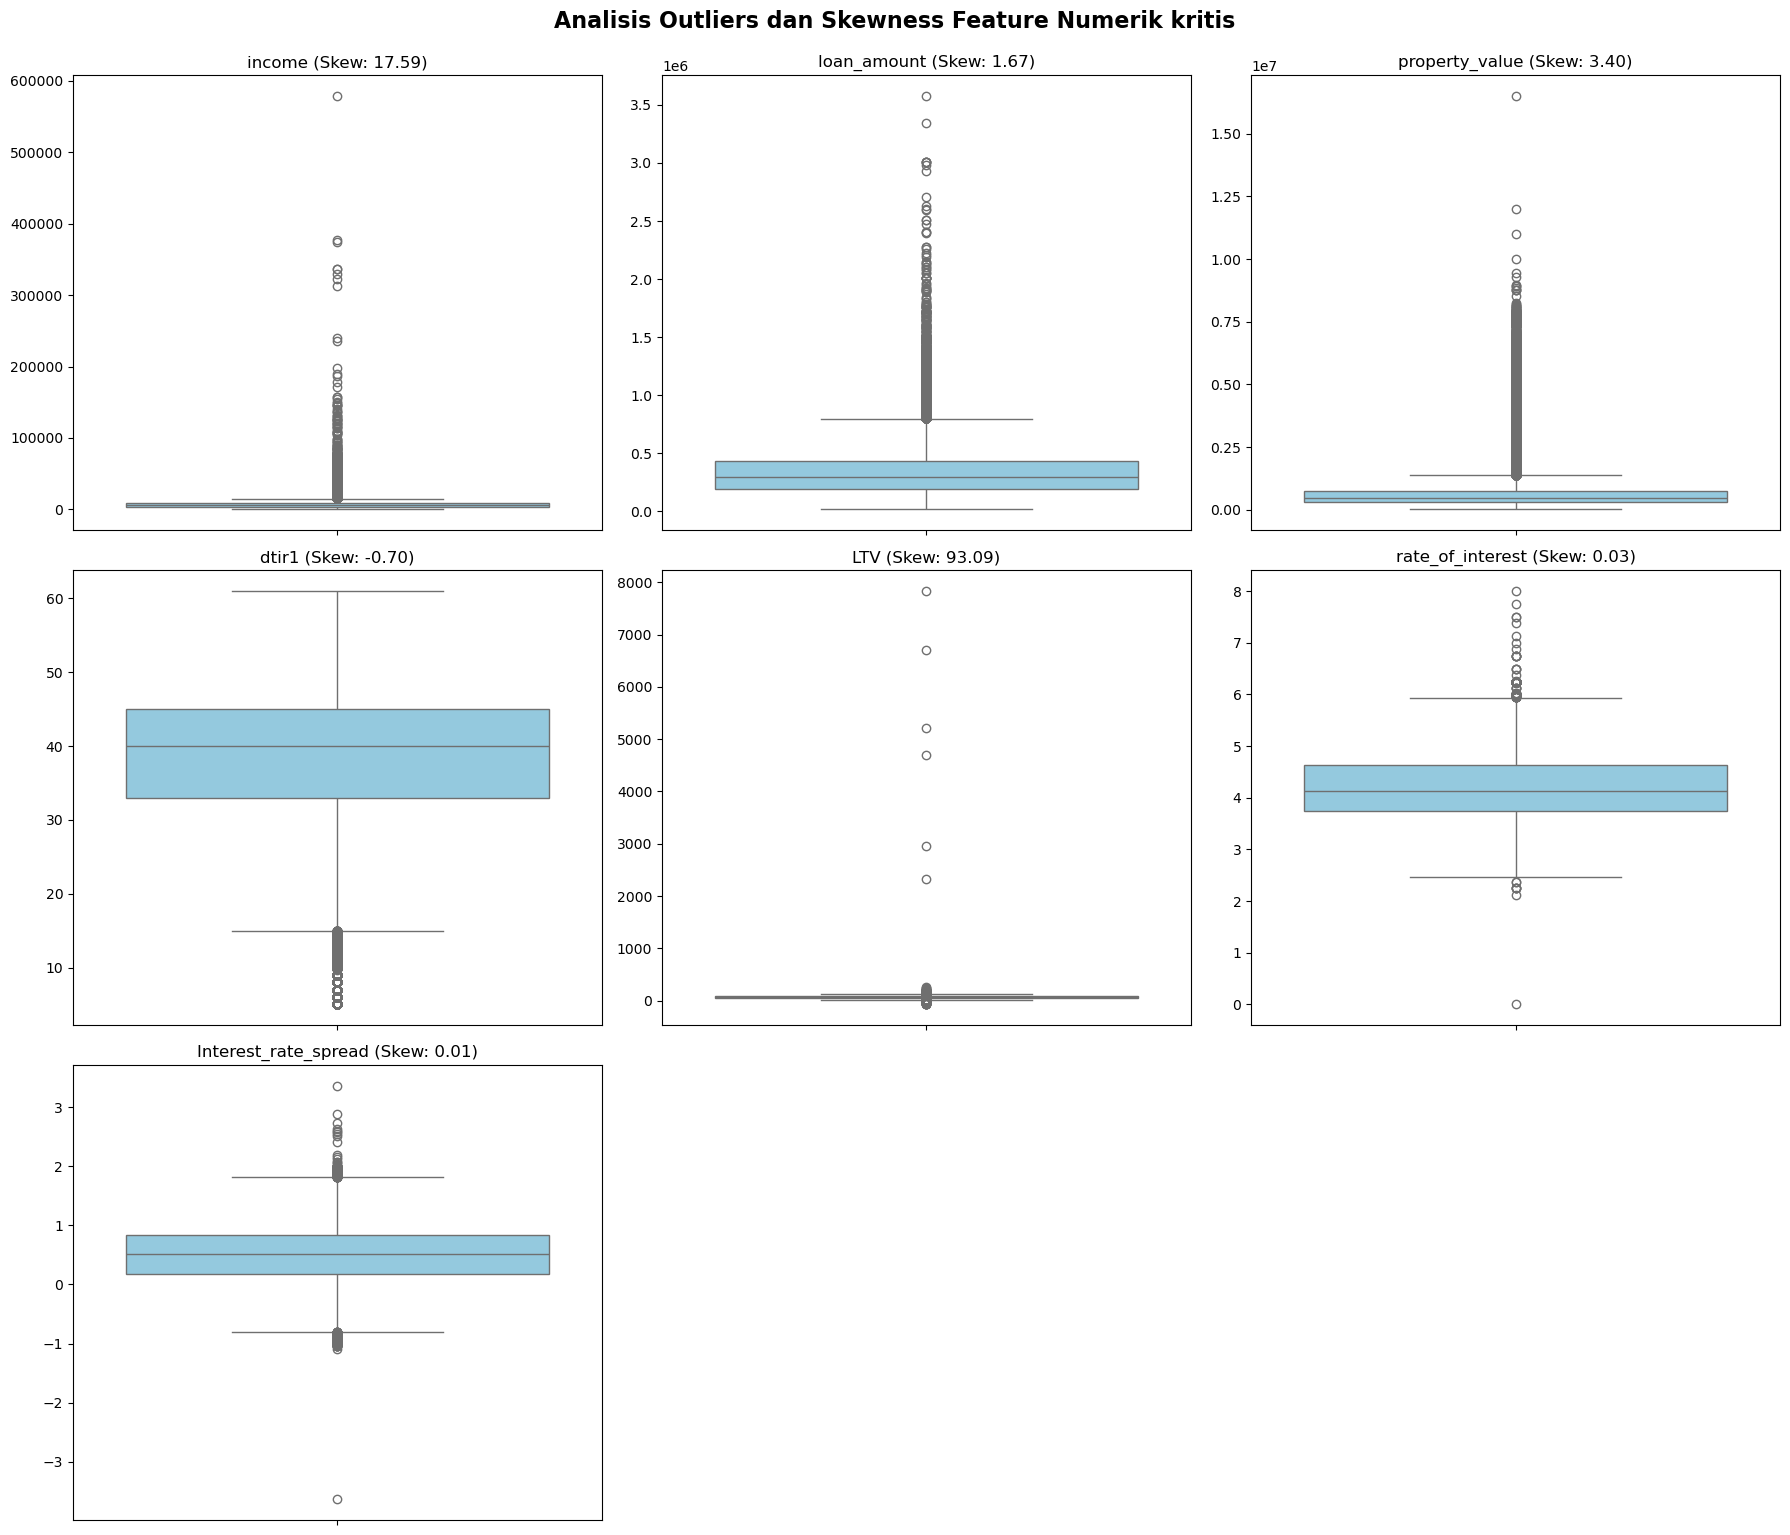

In [901]:
outlier_check_cols = [
    'income', 
    'loan_amount', 
    'property_value', 
    'dtir1',
    'LTV',
    'rate_of_interest',
    'Interest_rate_spread'
]

n_cols = 3
n_rows = (len(outlier_check_cols) + n_cols - 1) // n_cols 

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(outlier_check_cols):
    ax = plt.subplot(n_rows, n_cols, i + 1)
    
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    
    skewness = df[col].skew()
    ax.set_title(f'{col} (Skew: {skewness:.2f})', fontsize=12)
    ax.set_ylabel('')
    
plt.tight_layout()
plt.suptitle('Analisis Outliers dan Skewness Feature Numerik kritis', y=1.02, fontsize=16, fontweight='bold')
plt.show()

# Menganalisa outliers dari kolom penting

In [902]:
def iqr_capper(df, column_list):
    for col in column_list:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        upper_bound = Q3 + 1.5 * IQR
        lower_bound = Q1 - 1.5 * IQR
        
        outliers_count = df[(df[col] > upper_bound) | (df[col] < lower_bound)].shape[0]
        
        if outliers_count > 0:
            df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
            df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])         
    return df

outlier_prone_cols = [
    'income', 
    'loan_amount', 
    'property_value', 
    'dtir1',
    'rate_of_interest',
    'LTV',
    'Interest_rate_spread'
]

df = iqr_capper(df, outlier_prone_cols)

# IQR Capper = Outliers atas akan dibuat jadi batas atas semua (jadi tidak ada outliers)
# begitu juga outliers bawah, maka akan dibuat jadi batas bawah.

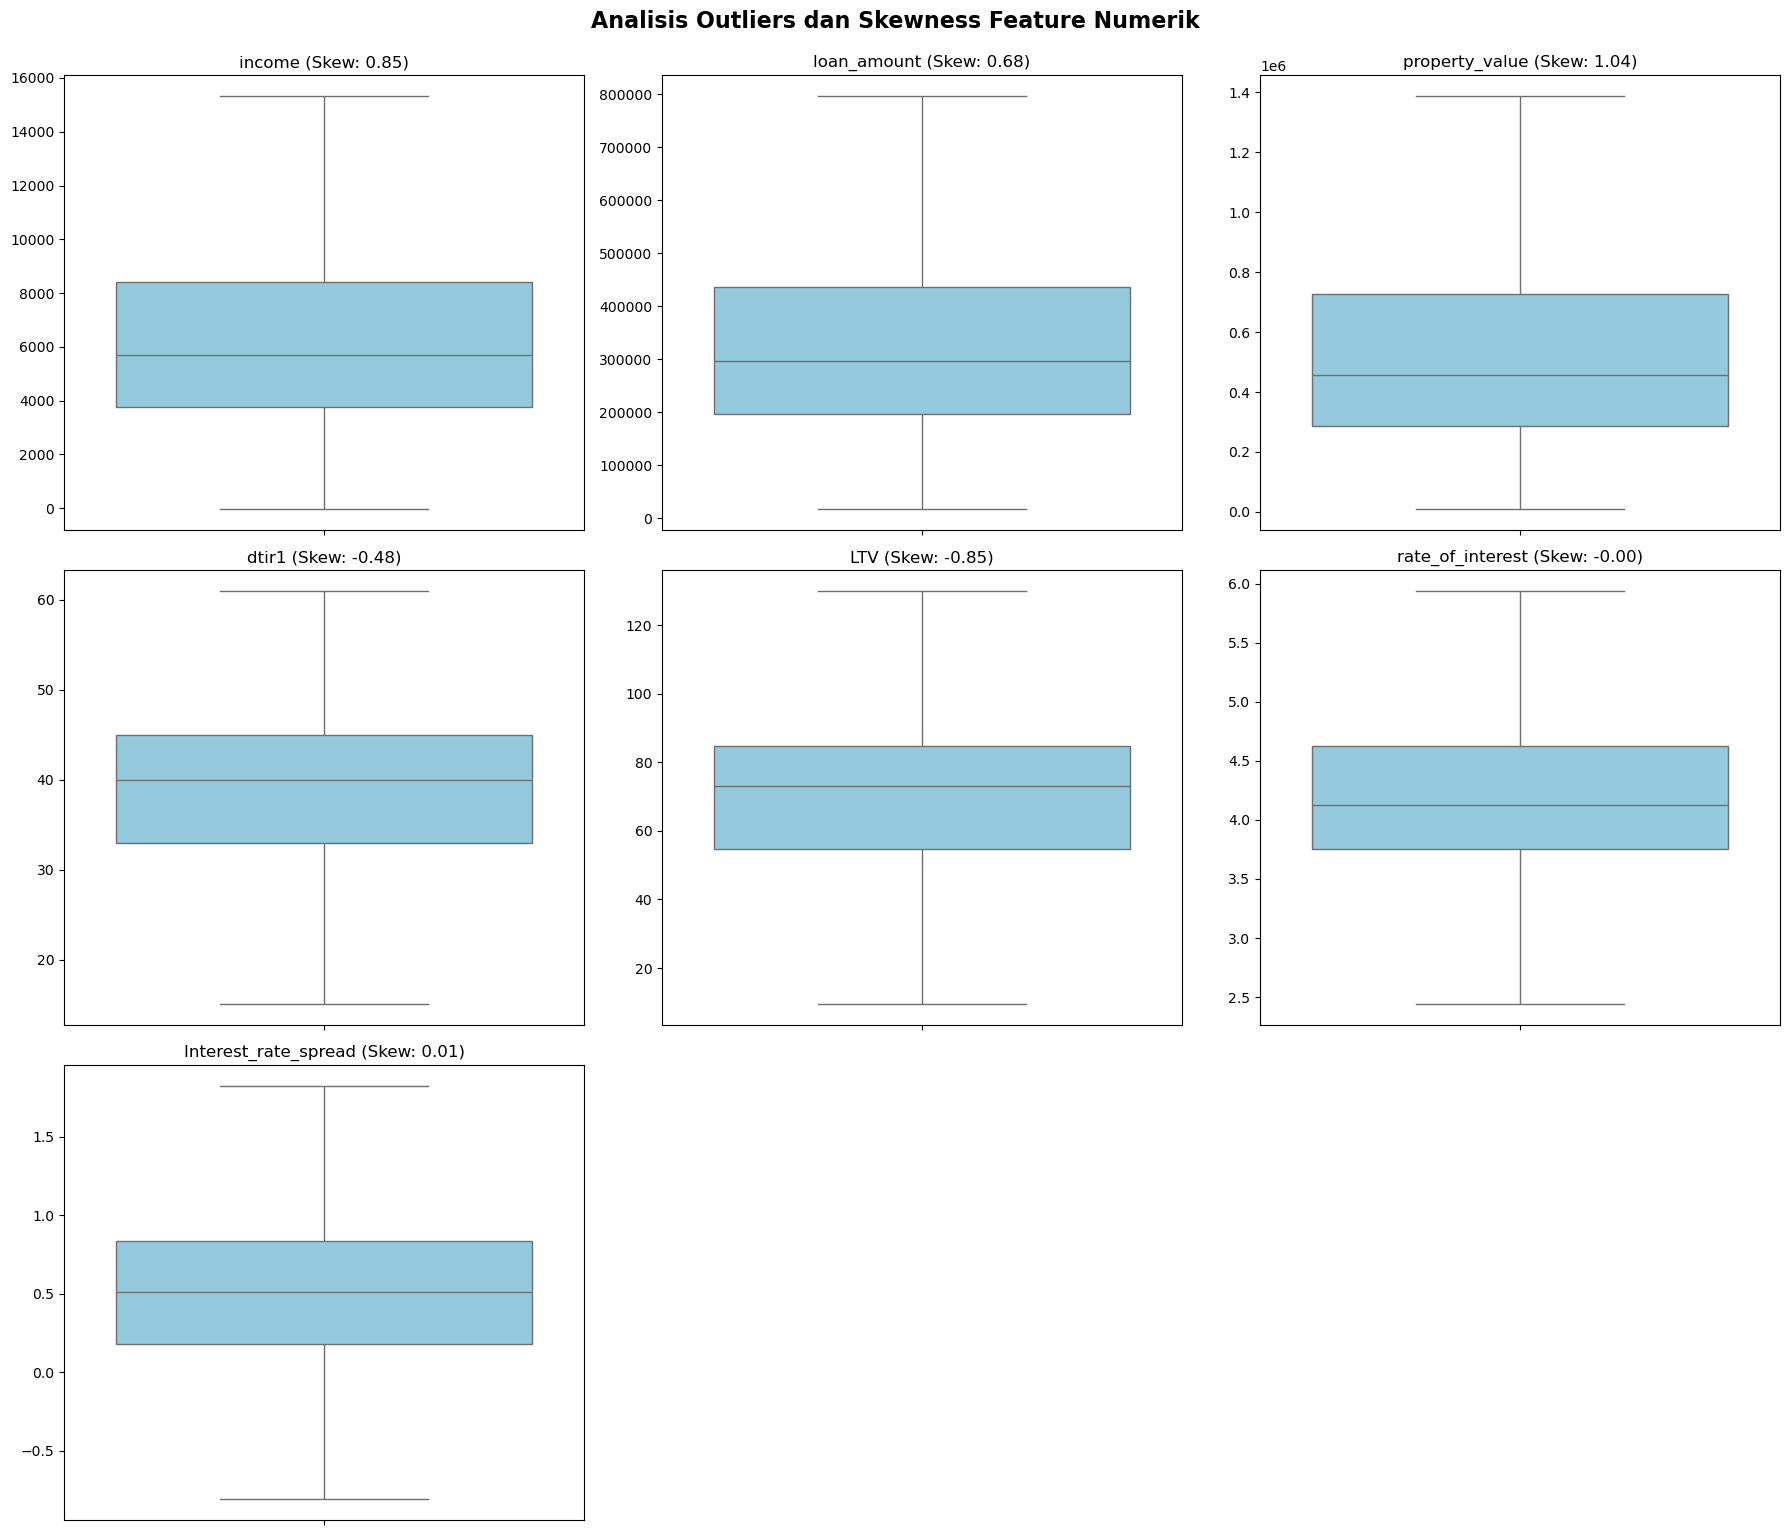

In [903]:
outlier_check_cols = [
    'income', 
    'loan_amount', 
    'property_value', 
    'dtir1',
    'LTV',
    'rate_of_interest',
    'Interest_rate_spread'
]

n_cols = 3
n_rows = (len(outlier_check_cols) + n_cols - 1) // n_cols 

plt.figure(figsize=(18, 5 * n_rows))

for i, col in enumerate(outlier_check_cols):
    ax = plt.subplot(n_rows, n_cols, i + 1)
    
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    
    skewness = df[col].skew()
    ax.set_title(f'{col} (Skew: {skewness:.2f})', fontsize=12)
    ax.set_ylabel('')
    
plt.tight_layout()
plt.suptitle('Analisis Outliers dan Skewness Feature Numerik', 
             y=1.02, fontsize=16, fontweight='bold')
plt.show()

In [904]:
all_numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

skewness_results = df[all_numerical_cols].skew().sort_values(ascending=False)

print("Skewness pada Semua Feature Numerik yang Tersisa")
print(skewness_results)
print("\nAnalisis Keputusan")

highly_skewed = skewness_results[abs(skewness_results) > 1.0]

if not highly_skewed.empty:
    print(f"{len(highly_skewed)} Feature MASIH perlu ditangani (Skewness > 1.0 atau < -1.0):")
    print(highly_skewed)
else:
    print("Semua Feature Numerik sudah cukup stabil atau Skewness-nya rendah.")

# Mengecek Skewd untuk tiap kolom

Skewness pada Semua Feature Numerik yang Tersisa
Upfront_charges         1.987903
Status                  1.176762
property_value          1.037751
income                  0.849842
loan_amount             0.682640
Interest_rate_spread    0.008316
Credit_Score            0.004767
ID                      0.000000
year                    0.000000
rate_of_interest       -0.001519
dtir1                  -0.478801
LTV                    -0.846508
term                   -2.172890
dtype: float64

Analisis Keputusan
4 Feature MASIH perlu ditangani (Skewness > 1.0 atau < -1.0):
Upfront_charges    1.987903
Status             1.176762
property_value     1.037751
term              -2.172890
dtype: float64


# **7. Feature Engineering**

In [ ]:
# --- 1. SKEWNESS FIXES (Box-Cox, Log, Yeo-Johnson) ---
# Apply Log(x+1) to property_value
df['property_value_log'] = np.log1p(df['property_value'])
# Apply Log(x+1) to term (Intermediate step for Yeo-Johnson)
df['term_log_new'] = np.log1p(df['term'])

# Fix 'Upfront_charges' (Box-Cox w/ Shift)
median_upfront_charges = df['Upfront_charges'].median()
df['Upfront_charges_filled'] = df['Upfront_charges'].fillna(median_upfront_charges)
min_val = df['Upfront_charges_filled'].min()
epsilon = 0.0001 
shift = np.abs(min_val) + epsilon if min_val <= 0 else 0 
df['Upfront_charges_boxcox'], _ = boxcox(df['Upfront_charges_filled'] + shift) 

# Apply Yeo-Johnson to the skewed term_log_new feature
pt = PowerTransformer(method='yeo-johnson', standardize=False)
df['term_yj'] = pt.fit_transform(df['term_log_new'].values.reshape(-1, 1))
print("Numerical Feature Transformations Complete.")


# --- 2. TARGET REGENERATION AND CLEANUP ---
# Recreate the target
if 'Status' in df.columns:
    le = LabelEncoder()
    df['Status_Encoded'] = le.fit_transform(df['Status'])

# Drop ALL raw, intermediate, and obsolete features.
cols_to_drop = [
    'Upfront_charges', 'property_value', 'term', 'Upfront_charges_filled', 
    'term_log_new', 'Status'
]
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')

# Clean target NaNs and define X and y
df_cleaned = df.dropna(subset=['Status_Encoded'])
X = df_cleaned.drop(columns=['Status_Encoded']) 
y = df_cleaned['Status_Encoded']

# --- 3. ONE-HOT ENCODING (MANDATORY FIX) ---
categorical_cols = X.select_dtypes(include=['object']).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
X = X_encoded
print(f"Feature Engineering Complete. Final X shape: {X.shape}")

Numerical Feature Transformations Complete.
Feature Engineering Complete. Final X shape: (148670, 50)


In [906]:
print(f"range of the property_value_log is between: {df['property_value_log'].min()} - {df['property_value_log'].max()}")

range of the property_value_log is between: 8.987321812850125 - 14.143375140509722


# **8. Modeling & Evaluation**

In [907]:
# Split Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train set size: {X_train.shape[0]} rows")

# Scale Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the BASELINE Model
model = LogisticRegression(solver='liblinear', random_state=42)
model.fit(X_train_scaled, y_train)

# Evaluate BASELINE
y_pred = model.predict(X_test_scaled)
print("\n--- BASELINE Model Performance (Step 8) ---")
print(classification_report(y_test, y_pred))

Train set size: 118936 rows

--- BASELINE Model Performance (Step 8) ---
              precision    recall  f1-score   support

           0       0.87      0.96      0.91     22406
           1       0.82      0.55      0.66      7328

    accuracy                           0.86     29734
   macro avg       0.84      0.75      0.78     29734
weighted avg       0.86      0.86      0.85     29734



# **9. Hyperparameter Tuning**

In [ ]:
# Assuming X_train_scaled and X_test_scaled are available from the preceding Step 8 block

# Train the OPTIMIZED Model with class_weight='balanced' (The strategic fix) 
model_balanced = LogisticRegression(
    solver='liblinear', 
    random_state=42, 
    class_weight='balanced'
)
model_balanced.fit(X_train_scaled, y_train)

# Evaluate OPTIMIZED Model
y_pred_balanced = model_balanced.predict(X_test_scaled)

print("\n--- OPTIMIZED Model Performance (Step 9) ---")
print(classification_report(y_test, y_pred_balanced))


--- OPTIMIZED Model Performance (Step 9) ---
              precision    recall  f1-score   support

           0       0.93      0.83      0.88     22406
           1       0.61      0.81      0.70      7328

    accuracy                           0.83     29734
   macro avg       0.77      0.82      0.79     29734
weighted avg       0.85      0.83      0.83     29734



# **10. CONCLUSION**

# **11. RECOMMENDATION**